In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
###converting excel to csv
from google.colab import files
import pandas as pd

uploaded = files.upload()
excel_file = list(uploaded.keys())[0]

df = pd.read_excel(excel_file)
csv_filename = excel_file.replace(".xlsx", ".csv")
df.to_csv(csv_filename, index=False)

files.download(csv_filename)

In [2]:
# =========================
# BLOCK 0 — Upload (Colab)
# =========================
from google.colab import files
uploaded = files.upload()
print("Uploaded:", list(uploaded.keys()))

Saving metadata_full.csv to metadata_full.csv
Saving methylation_full.csv to methylation_full.csv
Saving methylation_sub.csv to methylation_sub.csv
Uploaded: ['metadata_full.csv', 'methylation_full.csv', 'methylation_sub.csv']


In [17]:
# =========================
# BLOCK 1 — Imports + paths
# =========================
import pandas as pd
import numpy as np

FULL_X_PATH = "methylation_full.csv"
SUB_X_PATH  = "methylation_sub.csv"
META_PATH   = "metadata_full.csv"

ID_COL    = "submitter_id"
GROUP_COL = "tumor_stage"   # change if needed

# IMPORTANT: set delimiter explicitly
# If your header looks like: submitter_id,TSPY4,... use ","
# If it looks like: submitter_id<TAB>TSPY4... use "\t"
SEP = ","

In [18]:
# ==========================================
# BLOCK 2 — Load FULL/SUB methylation + meta
# ==========================================
# Load FULL methylation
X_full = pd.read_csv(FULL_X_PATH, sep=SEP)
if ID_COL not in X_full.columns:
    raise ValueError(f"{FULL_X_PATH} must contain column '{ID_COL}'")

X_full[ID_COL] = X_full[ID_COL].astype(str)
X_full = X_full.set_index(ID_COL)

# Convert gene columns to numeric
X_full = X_full.apply(pd.to_numeric, errors="coerce")

# Load SUB methylation
X_sub = pd.read_csv(SUB_X_PATH, sep=SEP)
if ID_COL not in X_sub.columns:
    raise ValueError(f"{SUB_X_PATH} must contain column '{ID_COL}'")

X_sub[ID_COL] = X_sub[ID_COL].astype(str)
X_sub = X_sub.set_index(ID_COL)

X_sub = X_sub.apply(pd.to_numeric, errors="coerce")

# Load metadata
meta = pd.read_csv(META_PATH, sep=SEP)
if ID_COL not in meta.columns:
    raise ValueError(f"{META_PATH} must contain column '{ID_COL}'")
if GROUP_COL not in meta.columns:
    raise ValueError(f"{META_PATH} must contain group column '{GROUP_COL}'")

meta[ID_COL] = meta[ID_COL].astype(str)
meta = meta.set_index(ID_COL)

print("Loaded:")
print("  X_full:", X_full.shape)
print("  X_sub :", X_sub.shape)
print("  meta  :", meta.shape)

Loaded:
  X_full: (2546, 359)
  X_sub : (50, 359)
  meta  : (2546, 5)


In [19]:
# =========================
# BLOCK 3 — Align samples
# =========================
# Keep only samples present in metadata
common_full = X_full.index.intersection(meta.index)
common_sub  = X_sub.index.intersection(meta.index)

X_full = X_full.loc[common_full].copy()
X_sub  = X_sub.loc[common_sub].copy()

meta_full = meta.loc[common_full].copy()
meta_sub  = meta.loc[common_sub].copy()

print("After sample alignment:")
print("  FULL shape:", X_full.shape)
print("  SUB shape :", X_sub.shape)
print("  Groups full:", meta_full[GROUP_COL].nunique())
print("  Groups sub :", meta_sub[GROUP_COL].nunique())

After sample alignment:
  FULL shape: (2546, 359)
  SUB shape : (50, 359)
  Groups full: 4
  Groups sub : 4


In [20]:
# =========================================================
# BLOCK 4 — CRITICAL FIX: Align genes + remove any NaN genes
# =========================================================
# 1) Use ONLY common genes
common_genes = X_full.columns.intersection(X_sub.columns)
X_full = X_full[common_genes].copy()
X_sub  = X_sub[common_genes].copy()

# 2) Enforce identical column order
X_sub = X_sub[X_full.columns].copy()

# 3) Remove genes with ANY missing values in either dataset
valid_genes = ~(X_full.isna().any(axis=0) | X_sub.isna().any(axis=0))
X_full = X_full.loc[:, valid_genes].copy()
X_sub  = X_sub.loc[:, valid_genes].copy()

print("After gene alignment + NaN filtering:")
print("  Genes FULL:", X_full.shape[1])
print("  Genes SUB :", X_sub.shape[1])
print("  Identical columns:", X_full.columns.equals(X_sub.columns))

After gene alignment + NaN filtering:
  Genes FULL: 359
  Genes SUB : 359
  Identical columns: True


In [7]:
# ==========================================
# BLOCK 5 — Standardize (fit FULL, apply SUB)
# ==========================================
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler(with_mean=True, with_std=True)
Z_full = scaler.fit_transform(X_full.values)   # fit on FULL
Z_sub  = scaler.transform(X_sub.values)        # apply to SUB

In [21]:
# ======================================
# BLOCK 6 — Total variance retained (%)
# ======================================
full_var = np.var(Z_full, axis=0, ddof=1).sum()
sub_var  = np.var(Z_sub,  axis=0, ddof=1).sum()
retained_pct = 100.0 * sub_var / full_var

print("Total variance (full):", round(full_var, 4))
print("Total variance (sub) :", round(sub_var, 4))
print("Variance retained (%):", round(retained_pct, 2))

Total variance (full): 359.1411
Total variance (sub) : 366.6692
Variance retained (%): 102.1


In [22]:
# =========================
# BLOCK 7 — PC1 preservation
# =========================
from sklearn.decomposition import PCA

pc1_full = PCA().fit(Z_full).explained_variance_ratio_[0]
pc1_sub  = PCA().fit(Z_sub ).explained_variance_ratio_[0]

print("PC1 full:", round(pc1_full, 4))
print("PC1 sub :", round(pc1_sub, 4))
print("Difference (sub-full):", round(pc1_sub - pc1_full, 4))

PC1 full: 0.4519
PC1 sub : 0.4691
Difference (sub-full): 0.0173


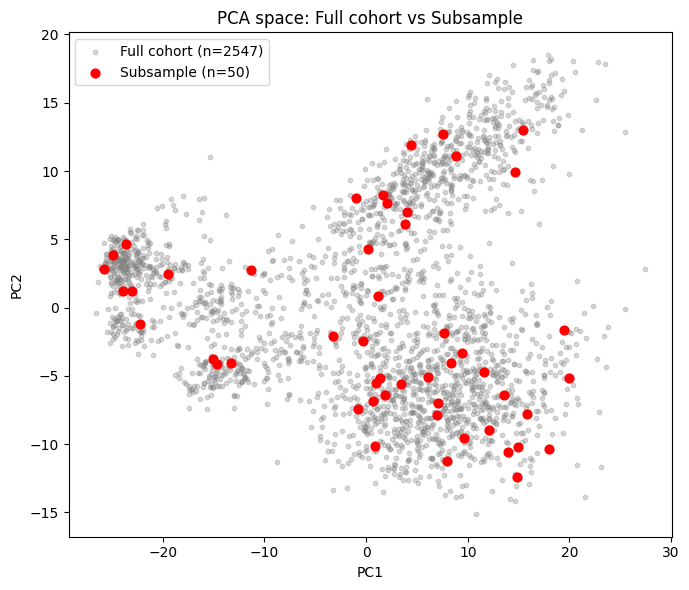

In [39]:
# ==========================================
# BLOCK — PCA overlay: full vs subsample
# ==========================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# Fit PCA on FULL cohort
pca = PCA(n_components=2)
pca_full = pca.fit_transform(Z_full)

# Project subsample onto the SAME PCA space
pca_sub = pca.transform(Z_sub)

plt.figure(figsize=(7,6))

# Plot full cohort (light gray)
plt.scatter(
    pca_full[:,0],
    pca_full[:,1],
    s=10,
    alpha=0.3,
    color="gray",
    label="Full cohort (n=2547)"
)

# Plot subsample (red)
plt.scatter(
    pca_sub[:,0],
    pca_sub[:,1],
    s=40,
    color="red",
    label="Subsample (n=50)"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title("PCA space: Full cohort vs Subsample")

plt.legend()

plt.tight_layout()
plt.show()

In [35]:
# ==========================================
# BLOCK 11 — Extract PC1 scores
# ==========================================

from sklearn.decomposition import PCA
import pandas as pd

pca = PCA()
pc_scores = pca.fit_transform(Z_full)

pc1 = pc_scores[:,0]

pc1_df = pd.DataFrame({
    "PC1": pc1
}, index=X_full.index)

# attach metadata
pc1_df = pc1_df.join(meta_full)

pc1_df.head()

,PC1,tumor_stage,age_at_diagnosis,race,gender,test_cancers
submitter_id,,,,,,
TCGA-DE-A4MB,5.417855,4,79.482192,3,0,2
TCGA-B6-A0RS,-21.053214,2,38.723288,3,0,1
TCGA-E8-A414,11.827340,3,45.901370,1,0,2
TCGA-AQ-A1H2,13.479523,3,84.816438,3,0,1
TCGA-QK-A6IG,15.676757,3,69.408219,3,1,5


In [36]:
from scipy.stats import spearmanr

rho, p = spearmanr(pc1_df["PC1"], pc1_df["age_at_diagnosis"])

print("PC1 vs age_at_diagnosis")
print("Spearman rho:", rho)
print("p-value:", p)

PC1 vs age_at_diagnosis
Spearman rho: -0.003077540555143658
p-value: 0.8766554862401303


In [37]:
from scipy.stats import f_oneway

def pc1_anova(var):

    groups = []

    for g in pc1_df[var].dropna().unique():
        groups.append(pc1_df.loc[pc1_df[var]==g,"PC1"])

    F,p = f_oneway(*groups)

    print(var)
    print("F:",round(F,4))
    print("p:",p)
    print()


for col in ["tumor_stage","race","gender","test_cancers"]:
    pc1_anova(col)

tumor_stage
F: 1.2866
p: 0.2772412775552231

race
F: 0.1947
p: 0.8231248897460468

gender
F: 0.265
p: 0.6067830201115675

test_cancers
F: 0.4957
p: 0.77967647583678



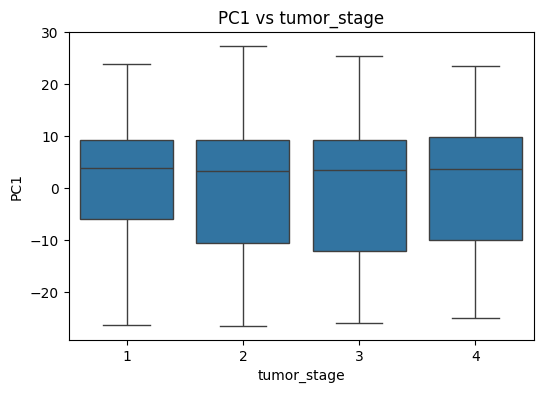

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
sns.boxplot(x="tumor_stage",y="PC1",data=pc1_df)
plt.title("PC1 vs tumor_stage")
plt.show()

In [23]:
# ==========================================
# BLOCK 7.5 — Cancer type F_ST (AMOVA-like)
# ==========================================
import numpy as np

def fst_amova_like(Z, labels):
    """
    AMOVA-like F_ST = SS_between / SS_total
    Z: standardized matrix (n_samples, n_features)
    labels: group labels (n_samples,)
    """
    Z = np.asarray(Z)
    labels = np.asarray(labels).astype(str)

    mu = Z.mean(axis=0, keepdims=True)

    ss_total = np.sum((Z - mu) ** 2)
    if ss_total <= 0:
        return np.nan

    ss_between = 0.0
    for c in np.unique(labels):
        idx = labels == c
        n_c = idx.sum()
        if n_c <= 0:
            continue
        mu_c = Z[idx].mean(axis=0, keepdims=True)
        ss_between += n_c * np.sum((mu_c - mu) ** 2)

    return float(ss_between / ss_total)

fst_full = fst_amova_like(Z_full, meta_full[GROUP_COL].values)
fst_sub  = fst_amova_like(Z_sub,  meta_sub[GROUP_COL].values)

print("Cancer type F_ST (full):", round(fst_full, 4))
print("Cancer type F_ST (sub) :", round(fst_sub, 4))
print("F_ST retained (%):", round(100.0 * fst_sub / fst_full, 2))

Cancer type F_ST (full): 0.0013
Cancer type F_ST (sub) : 0.0332
F_ST retained (%): 2594.63


In [24]:
# =========================================
# BLOCK 8 — Cancer-type distribution table
# =========================================
dist = pd.DataFrame({
    "full_n": meta_full[GROUP_COL].astype(str).value_counts(),
    "sub_n":  meta_sub[GROUP_COL].astype(str).value_counts()
}).fillna(0).astype(int)

dist["full_%"] = (100 * dist["full_n"] / dist["full_n"].sum()).round(2)
dist["sub_%"]  = (100 * dist["sub_n"]  / dist["sub_n"].sum()).round(2)
dist["Δ%"]     = (dist["sub_%"] - dist["full_%"]).round(2)

display(dist.sort_values("full_n", ascending=False))
# Sort before saving (same order as displayed)
dist_sorted = dist.sort_values("full_n", ascending=False)

# Save to CSV
file_name = "cancer_type_distribution_full_vs_sub.csv"
dist_sorted.to_csv(file_name)

print("Saved as:", file_name)

# Download file
from google.colab import files
files.download(file_name)

,full_n,sub_n,full_%,sub_%,Δ%
tumor_stage,,,,,
2,777,15,30.52,30.0,-0.52
1,671,17,26.36,34.0,7.64
3,604,11,23.72,22.0,-1.72
4,494,7,19.40,14.0,-5.40


Saved as: cancer_type_distribution_full_vs_sub.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

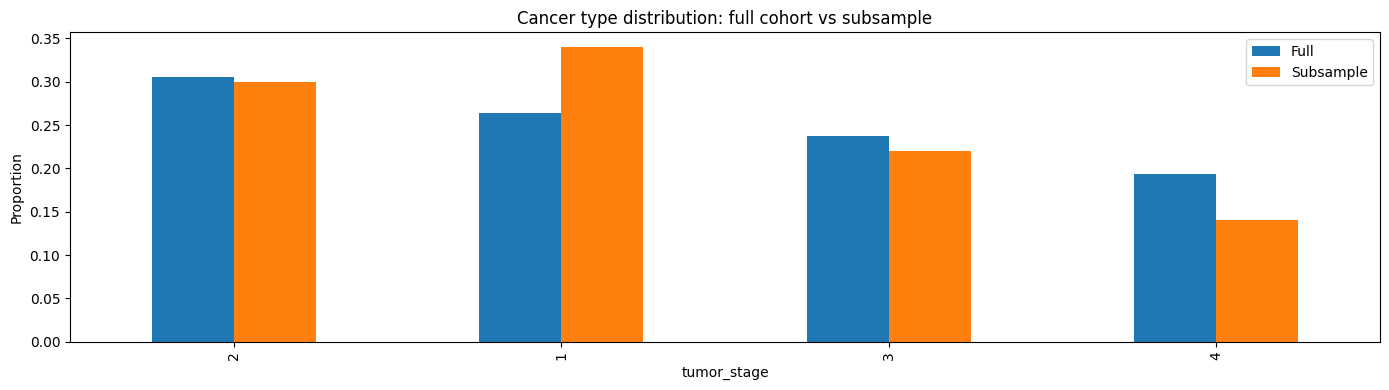

In [25]:
# ==========================================
# BLOCK 8.5 — Cancer type distribution barplot
# ==========================================
import matplotlib.pyplot as plt

plot_df = dist.copy()

# Convert counts to proportions (0-1) for plotting (optional; % also fine)
plot_df["Full"] = plot_df["full_n"] / plot_df["full_n"].sum()
plot_df["Subsample"] = plot_df["sub_n"] / plot_df["sub_n"].sum()

plot_df = plot_df[["Full", "Subsample"]].sort_values("Full", ascending=False)

ax = plot_df.plot(kind="bar", figsize=(14,4))
ax.set_ylabel("Proportion")
ax.set_title("Cancer type distribution: full cohort vs subsample")
plt.tight_layout()
plt.show()

In [29]:
# ==========================================
# BLOCK 9 — PERMANOVA (optional, structure)
# ==========================================
!pip -q install scikit-bio

from skbio.stats.distance import DistanceMatrix, permanova
from scipy.spatial.distance import pdist, squareform

def run_permanova(Z, groups, permutations=999):
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)
    return res.to_dict()

perm_full = run_permanova(Z_full, meta_full[GROUP_COL], permutations=999)
perm_sub  = run_permanova(Z_sub,  meta_sub[GROUP_COL],  permutations=999)

print("PERMANOVA full:", perm_full)
print("PERMANOVA sub :", perm_sub)

PERMANOVA full: {'method name': 'PERMANOVA', 'test statistic name': 'pseudo-F', 'sample size': 2546, 'number of groups': 4, 'test statistic': 1.0855339548849035, 'p-value': 0.349, 'number of permutations': 999}
PERMANOVA sub : {'method name': 'PERMANOVA', 'test statistic name': 'pseudo-F', 'sample size': 50, 'number of groups': 4, 'test statistic': 0.526511214758628, 'p-value': 0.957, 'number of permutations': 999}


In [30]:
print(meta_full.columns)
print(meta_full[GROUP_COL].nunique())
print(meta_full[GROUP_COL].value_counts().head())

Index(['tumor_stage', 'age_at_diagnosis', 'race', 'gender', 'test_cancers'], dtype='object')
4
tumor_stage
2    777
1    671
3    604
4    494
Name: count, dtype: int64


In [33]:
for col in ["tumor_stage","age_at_diagnosis","race","gender","test_cancers"]:
    print(col, meta_full[col].nunique())

tumor_stage 4
age_at_diagnosis 2385
race 3
gender 2
test_cancers 6


In [34]:
# ==========================================
# BLOCK 10 — PERMANOVA for all metadata variables
# ==========================================

print("Testing metadata variables as drivers of methylation variation\n")

for col in ["tumor_stage","age_at_diagnosis","race","gender","test_cancers"]:

    # skip columns with missing values
    groups = meta_full[col].dropna()

    # align samples
    idx = groups.index
    Z = Z_full[[X_full.index.get_loc(i) for i in idx]]

    res = run_permanova(Z, groups)

    print(f"{col}")
    print(" pseudo-F:", round(res["test statistic"],4))
    print(" p-value :", res["p-value"])
    print()

Testing metadata variables as drivers of methylation variation

tumor_stage
 pseudo-F: 1.0855
 p-value : 0.33

age_at_diagnosis
 pseudo-F: 0.9791
 p-value : 0.687

race
 pseudo-F: 0.4791
 p-value : 0.958

gender
 pseudo-F: 0.4676
 p-value : 0.838

test_cancers
 pseudo-F: 0.9264
 p-value : 0.548



In [31]:
from skbio.stats.distance import DistanceMatrix, permanova
from scipy.spatial.distance import pdist, squareform
import numpy as np
import pandas as pd

def permanova_with_r2(Z, groups, permutations=999):
    # distance matrix
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)

    # PERMANOVA test (pseudo-F + p-value)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)

    # ---- compute R^2 (variance explained) from distances ----
    g = pd.Series(groups.astype(str).values)
    n = len(g)

    # total sum of squares from distances
    ss_total = (D**2).sum() / (2 * n)

    # within-group SS: sum over groups of (sum of squared distances within group)/(2*ng)
    ss_within = 0.0
    for level in g.unique():
        idx = np.where(g.values == level)[0]
        ng = len(idx)
        if ng <= 1:
            continue
        Dw = D[np.ix_(idx, idx)]
        ss_within += (Dw**2).sum() / (2 * ng)

    ss_between = ss_total - ss_within
    r2 = ss_between / ss_total if ss_total > 0 else np.nan

    return {
        "pseudo-F": float(res["test statistic"]),
        "p-value": float(res["p-value"]),
        "permutations": int(res["number of permutations"]),
        "n": int(res["sample size"]),
        "k_groups": int(res["number of groups"]),
        "R2": float(r2)
    }

perm_full = permanova_with_r2(Z_full, meta_full[GROUP_COL], permutations=999)
perm_sub  = permanova_with_r2(Z_sub,  meta_sub[GROUP_COL],  permutations=999)

print("PERMANOVA full:", perm_full)
print("PERMANOVA sub :", perm_sub)

PERMANOVA full: {'pseudo-F': 1.0855339548849035, 'p-value': 0.332, 'permutations': 999, 'n': 2546, 'k_groups': 4, 'R2': 0.0012794788007907786}
PERMANOVA sub : {'pseudo-F': 0.526511214758628, 'p-value': 0.951, 'permutations': 999, 'n': 50, 'k_groups': 4, 'R2': 0.03319775380913011}


Random subsampling R2 mean: 0.0584
Random subsampling R2 std : 0.0199
Observed SUB R2          : 0.0332
Observed percentile       : 6.0 %


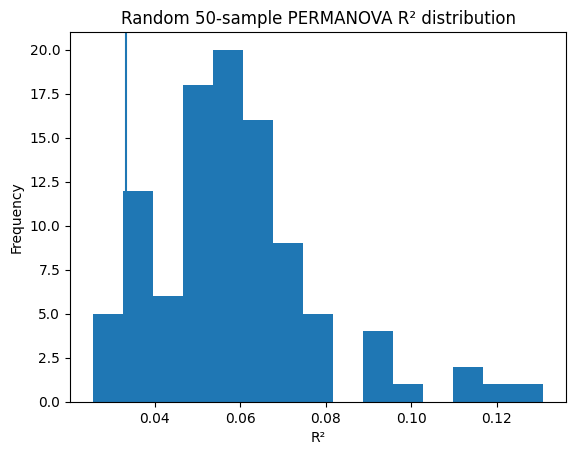

In [32]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist, squareform
from skbio.stats.distance import DistanceMatrix
from skbio.stats.distance import permanova
import matplotlib.pyplot as plt

# -----------------------------
# Helper: compute PERMANOVA R2
# -----------------------------
def permanova_r2(Z, groups, permutations=0):
    """
    Computes PERMANOVA R2 (variance explained).
    Permutations set to 0 for speed in repeated subsampling.
    """
    D = squareform(pdist(Z, metric="euclidean"))
    dm = DistanceMatrix(D)

    # Run permanova (no permutations needed for R2)
    res = permanova(dm, grouping=groups.astype(str).values, permutations=permutations)

    g = pd.Series(groups.astype(str).values)
    n = len(g)

    ss_total = (D**2).sum() / (2 * n)

    ss_within = 0.0
    for level in g.unique():
        idx = np.where(g.values == level)[0]
        ng = len(idx)
        if ng <= 1:
            continue
        Dw = D[np.ix_(idx, idx)]
        ss_within += (Dw**2).sum() / (2 * ng)

    ss_between = ss_total - ss_within
    r2 = ss_between / ss_total if ss_total > 0 else np.nan

    return float(r2)

# -----------------------------------------
# Random subsampling from FULL
# -----------------------------------------

n_iterations = 100
subset_size = 50
random_r2 = []

np.random.seed(42)

for i in range(n_iterations):
    idx = np.random.choice(Z_full.shape[0], subset_size, replace=False)
    Z_sample = Z_full[idx]
    groups_sample = meta_full.iloc[idx][GROUP_COL]

    r2 = permanova_r2(Z_sample, groups_sample, permutations=0)
    random_r2.append(r2)

random_r2 = np.array(random_r2)

# -----------------------------------------
# Compare with your observed SUB R2
# -----------------------------------------

observed_sub_r2 = perm_sub["R2"]

mean_r2 = random_r2.mean()
std_r2 = random_r2.std()
percentile = (random_r2 < observed_sub_r2).mean() * 100

print("Random subsampling R2 mean:", round(mean_r2, 4))
print("Random subsampling R2 std :", round(std_r2, 4))
print("Observed SUB R2          :", round(observed_sub_r2, 4))
print("Observed percentile       :", round(percentile, 1), "%")

# -----------------------------------------
# Plot distribution
# -----------------------------------------

plt.figure()
plt.hist(random_r2, bins=15)
plt.axvline(observed_sub_r2)
plt.title("Random 50-sample PERMANOVA R² distribution")
plt.xlabel("R²")
plt.ylabel("Frequency")
plt.show()

In [40]:
print(meta.columns)

Index(['tumor_stage', 'age_at_diagnosis', 'race', 'gender', 'test_cancers'], dtype='object')


In [41]:
meta_full["test_cancers"].unique()

array([2, 1, 5, 4, 6, 3])